# First-derivative transition in the momentum scaling law

This notebook studies only the **first time-domain transition** in the total loss curve. The transition is detected from an abrupt change in the empirical first log-derivative $d\log L/d\log k$; it is not defined by equating separately fitted signal and transient terms. Label noise is included with $\sigma=0.1$, but the later signal-to-noise transition is not analyzed. The PLK simulation runs on a CUDA or Apple MPS GPU.

In [100]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import torch

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    DTYPE = torch.float64
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
    DTYPE = torch.float32
else:
    raise RuntimeError("A CUDA or Apple MPS GPU is required.")

OUTPUT_DIR = Path("results/new_scaling")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"device={DEVICE}, dtype={DTYPE}, torch={torch.__version__}")

device=cuda, dtype=torch.float64, torch=2.12.1+cu130


## Corrected loss prediction

Write $g=1-\rho$ and $\eta_\rho=\eta/g$. In the mixed regime, the unit-prefactor scaling predictions are

$$L_{\rm Polyak}(k)=\underbrace{\rho^k}_{T(k)}+\underbrace{(\eta_\rho k)^{-s}}_{S(k)}+\underbrace{\frac{\sigma^2}{B}\eta_\rho}_{N},$$

$$L_{\rm Nesterov}(k)=\underbrace{\min\{1,(\eta k)^{-s}\}\rho^k}_{T(k)}+\underbrace{(\eta_\rho k)^{-s}}_{S(k)}+\underbrace{\frac{\sigma^2}{B}\min\{\eta_\rho,\eta_\rho^{1/\beta}\}}_{N}.$$

The Nesterov transient is the corrected expression in Theorem 5.2 of `paper.pdf`, not the older $p^k$ expression in Appendix G.2. The term decomposition is used only to construct the fitted theoretical total loss; it is not used to define the transition point.

In [101]:
B = 64
ETA = 0.06
BETA = 4.0
S = 0.5
SIGMA = 0.65
DIM = 4096
RUNS = 100
TRAIN_STEPS = 5000000
N_CHECKPOINTS = 1_200
SEED = 7
DISPLAY_GAP = 0.03       # rho = 0.995, matching the paper's representative setting
GAP_MIN = 0.0017          # above the Polyak stability scale eta / B for B=64
GAP_MAX = 0.03            # high-momentum range with the first transition after 2 / eta
N_GAPS = 180
K_MIN = 1.0
K_MAX = float(TRAIN_STEPS)
N_K = 40_000
DERIVATIVE_GRID_POINTS = 2_000
DERIVATIVE_SMOOTH_WINDOW = 31
DERIVATIVE_SEARCH_MIN = 2.0 / ETA
DERIVATIVE_SEARCH_MAX = 10_000.0
ALGORITHMS = ("polyak", "nesterov")
COLORS = {"polyak": "#D94B3D", "nesterov": "#2F5DA8"}

K_GRID = torch.logspace(
    np.log10(K_MIN), np.log10(K_MAX), N_K, device=DEVICE, dtype=DTYPE
)
GAP_GRID = torch.logspace(
    np.log10(GAP_MIN), np.log10(GAP_MAX), N_GAPS, device=DEVICE, dtype=DTYPE
)

## GPU experiment and scaling-law fit

We simulate the finite-dimensional PLK model with fresh curvature-aligned Gaussian gradient noise at every step. The empirical curve is the exact population excess risk averaged over independent GPU replicas. Following Appendix G.2, separate nonnegative coefficients $C_T,C_S,C_N$ are fitted by relative least squares, while the corrected theoretical term shapes remain fixed.

In [102]:
CHECKPOINTS = np.unique(np.concatenate((
    np.asarray([0], dtype=int),
    np.geomspace(1, TRAIN_STEPS, N_CHECKPOINTS).round().astype(int),
))).astype(int)

@torch.no_grad()
def simulate_empirical_curve(algorithm):
    torch.manual_seed(SEED + (0 if algorithm == "polyak" else 10_000))
    j = torch.arange(1, DIM + 1, device=DEVICE, dtype=DTYPE)
    lam = j.pow(-BETA)
    sqrt_lam = lam.sqrt()
    theta_star = j.pow(-0.5 * (1.0 + (S - 1.0) * BETA))
    current = -theta_star.expand(RUNS, -1).clone()
    previous = current.clone()
    rho = 1.0 - DISPLAY_GAP
    checkpoint_set = set(CHECKPOINTS.tolist())
    saved_steps = [0]
    saved_loss = [float((0.5 * (current.square() * lam).sum(dim=1)).mean().item())]
    for step in range(1, TRAIN_STEPS + 1):
        momentum = current - previous
        evaluation = current + rho * momentum if algorithm == "nesterov" else current
        evaluation_loss = 0.5 * (evaluation.square() * lam).sum(dim=1)
        noise_scale = ((evaluation_loss + SIGMA**2) / B).sqrt().unsqueeze(1)
        gradient = evaluation * lam + torch.randn_like(evaluation) * sqrt_lam * noise_scale
        new = current + rho * momentum - ETA * gradient
        previous, current = current, new
        if step in checkpoint_set:
            loss = 0.5 * (current.square() * lam).sum(dim=1)
            saved_steps.append(step)
            saved_loss.append(float(loss.mean().item()))
        if step % 50_000 == 0:
            print(f"  {algorithm}: {step:,}/{TRAIN_STEPS:,} steps", flush=True)
    return np.asarray(saved_steps), np.asarray(saved_loss)

experimental_results = {}
for algorithm in ALGORITHMS:
    print(f"simulating {algorithm} on {DEVICE} ...", flush=True)
    steps, empirical = simulate_empirical_curve(algorithm)
    experimental_results[algorithm] = {"steps": steps, "empirical": empirical}
    print(f"  final empirical loss={empirical[-1]:.6e}", flush=True)

simulating polyak on cuda ...


  polyak: 50,000/5,000,000 steps
  polyak: 100,000/5,000,000 steps
  polyak: 150,000/5,000,000 steps
  polyak: 200,000/5,000,000 steps
  polyak: 250,000/5,000,000 steps
  polyak: 300,000/5,000,000 steps
  polyak: 350,000/5,000,000 steps
  polyak: 400,000/5,000,000 steps
  polyak: 450,000/5,000,000 steps
  polyak: 500,000/5,000,000 steps
  polyak: 550,000/5,000,000 steps
  polyak: 600,000/5,000,000 steps
  polyak: 650,000/5,000,000 steps
  polyak: 700,000/5,000,000 steps
  polyak: 750,000/5,000,000 steps
  polyak: 800,000/5,000,000 steps
  polyak: 850,000/5,000,000 steps
  polyak: 900,000/5,000,000 steps
  polyak: 950,000/5,000,000 steps
  polyak: 1,000,000/5,000,000 steps
  polyak: 1,050,000/5,000,000 steps
  polyak: 1,100,000/5,000,000 steps
  polyak: 1,150,000/5,000,000 steps
  polyak: 1,200,000/5,000,000 steps
  polyak: 1,250,000/5,000,000 steps
  polyak: 1,300,000/5,000,000 steps
  polyak: 1,350,000/5,000,000 steps
  polyak: 1,400,000/5,000,000 steps
  polyak: 1,450,000/5,000,000 s

In [103]:
def theory_matrix_at_steps(steps, algorithm, gap=DISPLAY_GAP):
    k = np.maximum(np.asarray(steps, dtype=float), 1.0)
    rho = 1.0 - gap
    eta_rho = ETA / gap
    signal = (eta_rho * k) ** (-S)
    if algorithm == "polyak":
        transient = rho**k
        noise_level = SIGMA**2 / B * eta_rho
    else:
        transient = np.minimum(1.0, (ETA * k) ** (-S)) * rho**k
        noise_level = SIGMA**2 / B * min(eta_rho, eta_rho ** (1.0 / BETA))
    return np.column_stack((transient, signal, np.full_like(k, noise_level)))

def nonnegative_lstsq(x, y):
    best, best_error = np.zeros(x.shape[1]), np.inf
    for mask in range(1, 1 << x.shape[1]):
        active = [index for index in range(x.shape[1]) if mask & (1 << index)]
        active_coef, *_ = np.linalg.lstsq(x[:, active], y, rcond=None)
        if np.any(active_coef < 0):
            continue
        coefficient = np.zeros(x.shape[1])
        coefficient[active] = active_coef
        error = np.mean((x @ coefficient - y) ** 2)
        if error < best_error:
            best, best_error = coefficient, error
    return best

fitted_coefficients = {}
for algorithm in ALGORITHMS:
    result = experimental_results[algorithm]
    terms = theory_matrix_at_steps(result["steps"], algorithm)
    valid = (result["steps"] > 0) & ((ETA / DISPLAY_GAP) * result["steps"] >= 1.0)
    scale = np.maximum(result["empirical"][valid], np.finfo(float).tiny)
    coefficient = nonnegative_lstsq(terms[valid] / scale[:, None], np.ones(valid.sum()))
    result.update(terms=terms, prediction=terms @ coefficient, valid=valid)
    fitted_coefficients[algorithm] = coefficient
    print(algorithm, dict(zip(("C_T", "C_S", "C_N"), coefficient)))

polyak {'C_T': np.float64(0.12126392705380178), 'C_S': np.float64(0.17422262302696404), 'C_N': np.float64(0.26327458785705943)}
nesterov {'C_T': np.float64(0.09146999947499557), 'C_S': np.float64(0.16105111798489452), 'C_N': np.float64(0.17319025289400483)}


In [104]:
def first_derivative_transition(steps, loss):
    """Locate the strongest abrupt change of d log(loss) / d log(step)."""
    steps = np.asarray(steps, dtype=float)
    loss = np.asarray(loss, dtype=float)
    valid = (steps > 0) & np.isfinite(loss) & (loss > 0)
    x = np.log(steps[valid])
    y = np.log(loss[valid])
    x_uniform = np.linspace(x.min(), x.max(), DERIVATIVE_GRID_POINTS)
    y_uniform = np.interp(x_uniform, x, y)
    window = int(DERIVATIVE_SMOOTH_WINDOW)
    if window % 2 == 0:
        window += 1
    pad = window // 2
    kernel = np.ones(window, dtype=float) / window
    y_smooth = np.convolve(np.pad(y_uniform, pad, mode="reflect"), kernel, mode="valid")
    first_derivative = np.gradient(y_smooth, x_uniform)
    derivative_jump = np.abs(np.gradient(first_derivative, x_uniform))
    k_uniform = np.exp(x_uniform)
    search = (k_uniform >= DERIVATIVE_SEARCH_MIN) & (k_uniform <= DERIVATIVE_SEARCH_MAX)
    search[:2 * window] = False
    search[-2 * window:] = False
    score = np.where(search, derivative_jump, -np.inf)
    index = int(np.argmax(score))
    return {
        "k_transition": float(k_uniform[index]), "index": index,
        "k_grid": k_uniform, "smoothed_log_loss": y_smooth,
        "first_derivative": first_derivative, "derivative_jump": derivative_jump,
    }

derivative_diagnostics = {}
for algorithm in ALGORITHMS:
    result = experimental_results[algorithm]
    derivative_diagnostics[algorithm] = {
        "experiment": first_derivative_transition(result["steps"], result["empirical"]),
        "theory": first_derivative_transition(result["steps"], result["prediction"]),
    }
    print(algorithm, {
        name: diagnostic["k_transition"]
        for name, diagnostic in derivative_diagnostics[algorithm].items()
    })

polyak {'experiment': 75.85794732631076, 'theory': 140.63516704013722}
nesterov {'experiment': 9284.833702224332, 'theory': 104.89380296818719}


## Figure 1: GPU experiment and fitted scaling-law prediction

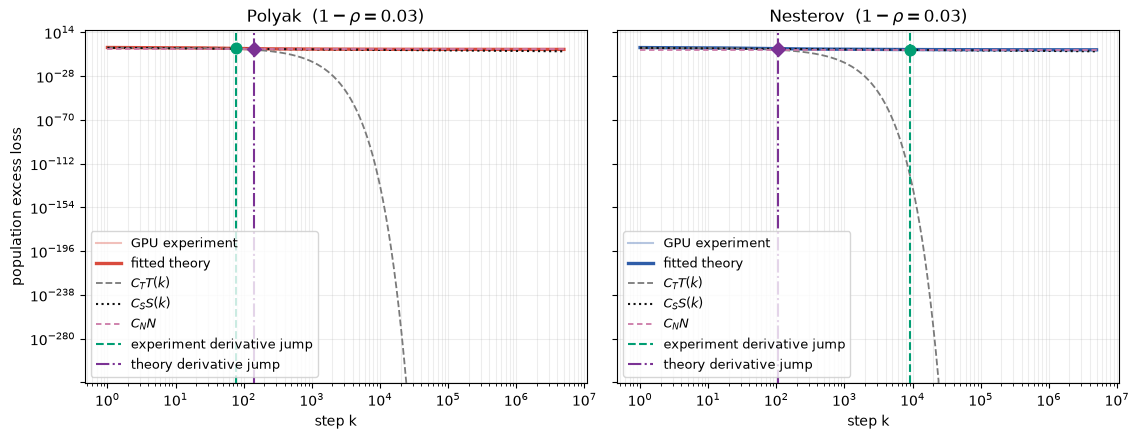

{'polyak': {'experiment': 75.85794732631076, 'theory': 140.63516704013722},
 'nesterov': {'experiment': 9284.833702224332, 'theory': 104.89380296818719}}

In [105]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5), sharey=True)
display_transitions = {}
k_np = K_GRID.cpu().numpy()

for axis, algorithm in zip(axes, ALGORITHMS):
    result = experimental_results[algorithm]
    coefficient = fitted_coefficients[algorithm]
    k_experiment = derivative_diagnostics[algorithm]["experiment"]["k_transition"]
    k_theory = derivative_diagnostics[algorithm]["theory"]["k_transition"]
    display_transitions[algorithm] = {"experiment": k_experiment, "theory": k_theory}
    fitted_parts = result["terms"] * coefficient[None, :]
    positive = result["steps"] > 0
    experiment_loss = float(np.interp(
        np.log(k_experiment), np.log(result["steps"][positive]), result["empirical"][positive]
    ))
    theory_loss = float(np.interp(
        np.log(k_theory), np.log(result["steps"][positive]), result["prediction"][positive]
    ))

    axis.loglog(result["steps"][positive], result["empirical"][positive],
                color=COLORS[algorithm], alpha=0.35, lw=1.5, label="GPU experiment")
    axis.loglog(result["steps"][positive], result["prediction"][positive],
                color=COLORS[algorithm], lw=2.4, label="fitted theory")
    axis.loglog(result["steps"][positive], fitted_parts[positive, 0], "--",
                color="#7A7A7A", lw=1.3, label=r"$C_TT(k)$")
    axis.loglog(result["steps"][positive], fitted_parts[positive, 1], ":",
                color="#111111", lw=1.5, label=r"$C_SS(k)$")
    axis.loglog(result["steps"][positive], fitted_parts[positive, 2],
                color="#CC79A7", ls=(0, (3, 2)), lw=1.3, label=r"$C_NN$")
    axis.axvline(k_experiment, color="#009E73", ls="--", lw=1.5, label="experiment derivative jump")
    axis.axvline(k_theory, color="#7B3294", ls="-.", lw=1.5, label="theory derivative jump")
    axis.scatter([k_experiment], [experiment_loss], marker="o", s=58, color="#009E73", zorder=5)
    axis.scatter([k_theory], [theory_loss], marker="D", s=50, color="#7B3294", zorder=5)
    axis.set(title=algorithm.capitalize() + rf"  ($1-\rho={DISPLAY_GAP}$)", xlabel="step k")
    axis.grid(True, which="both", alpha=0.22)
    axis.legend(fontsize=9)
axes[0].set_ylabel("population excess loss")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "scaling_prediction_with_derivative_transition.png", dpi=220, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "scaling_prediction_with_derivative_transition.pdf", bbox_inches="tight")
plt.show()
display_transitions

## Standalone total-loss prediction

This figure overlays the GPU empirical total loss and the fitted theoretical total $\widehat L(k)=C_TT(k)+C_SS(k)+C_NN$, without showing the component curves. Circle and diamond markers show the strongest first-derivative change detected independently from the experimental and theoretical total curves.

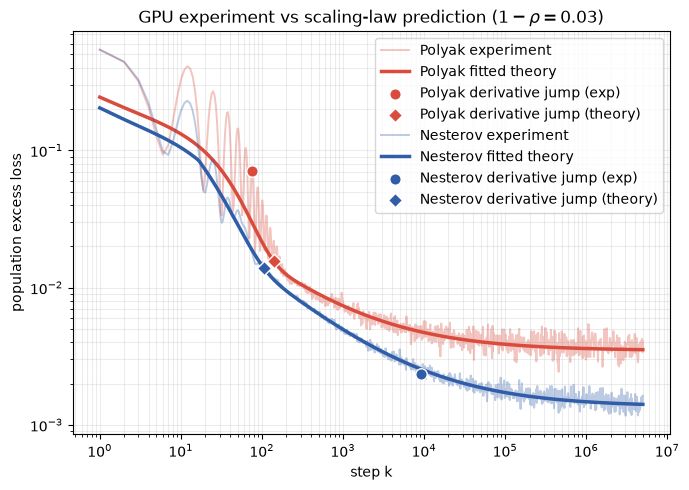

In [106]:
fig, ax = plt.subplots(figsize=(7.0, 5.0))
for algorithm in ALGORITHMS:
    result = experimental_results[algorithm]
    positive = result["steps"] > 0
    k_experiment = display_transitions[algorithm]["experiment"]
    k_theory = display_transitions[algorithm]["theory"]
    experiment_loss = float(np.interp(
        np.log(k_experiment), np.log(result["steps"][positive]), result["empirical"][positive]
    ))
    theory_loss = float(np.interp(
        np.log(k_theory), np.log(result["steps"][positive]), result["prediction"][positive]
    ))
    ax.loglog(result["steps"][positive], result["empirical"][positive],
              color=COLORS[algorithm], alpha=0.32, lw=1.4,
              label=algorithm.capitalize() + " experiment")
    ax.loglog(result["steps"][positive], result["prediction"][positive],
              color=COLORS[algorithm], lw=2.5,
              label=algorithm.capitalize() + " fitted theory")
    ax.scatter([k_experiment], [experiment_loss], color=COLORS[algorithm], marker="o", s=68,
               edgecolor="white", zorder=5, label=algorithm.capitalize() + " derivative jump (exp)")
    ax.scatter([k_theory], [theory_loss], color=COLORS[algorithm], marker="D", s=52,
               edgecolor="white", zorder=5, label=algorithm.capitalize() + " derivative jump (theory)")
ax.set(
    xlabel="step k", ylabel="population excess loss",
    title=rf"GPU experiment vs scaling-law prediction ($1-\rho={DISPLAY_GAP}$)",
)
ax.grid(True, which="both", alpha=0.23)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "total_loss_experiment_vs_theory.png", dpi=220, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "total_loss_experiment_vs_theory.pdf", bbox_inches="tight")
plt.show()

## Figure 2: derivative-detected transition versus $1-\rho$

For each momentum gap, the fitted theoretical total loss is constructed first. The transition is then detected solely from the strongest change in $d\log L/d\log k$, using exactly the same smoothing and search window as for the empirical curve. The search starts at $k=2/\eta$ so that Nesterov's algebraic kink from the literal $\min\{1,(\eta k)^{-s}\}$ expression at $k=1/\eta$ is not misidentified as the dynamical transition. The experimental marker at $1-\rho=0.005$ is obtained directly from the GPU loss trajectory; no signal/transient equality is used.

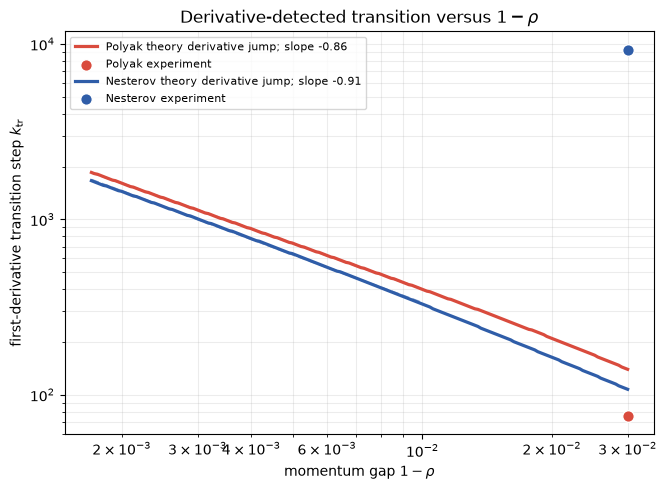

{'polyak': {'small_gap_loglog_slope': -0.8632719229552324,
  'intercept': 2.016498914536914},
 'nesterov': {'small_gap_loglog_slope': -0.9118530826336165,
  'intercept': 1.6126621626736242}}

In [107]:
gap_np = GAP_GRID.cpu().numpy()
k_np = K_GRID.cpu().numpy()
transition_by_algorithm = {}
for algorithm in ALGORITHMS:
    coefficient = fitted_coefficients[algorithm]
    transition_by_algorithm[algorithm] = np.asarray([
        first_derivative_transition(
            k_np, theory_matrix_at_steps(k_np, algorithm, float(gap)) @ coefficient
        )["k_transition"]
        for gap in gap_np
    ])

fig, ax = plt.subplots(figsize=(6.8, 5.0))
fit_summary = {}
for algorithm in ALGORITHMS:
    transition_np = transition_by_algorithm[algorithm]
    valid = np.isfinite(transition_np)
    small_gap = valid & (gap_np <= 0.01)
    slope, intercept = np.polyfit(np.log(gap_np[small_gap]), np.log(transition_np[small_gap]), 1)
    fit_summary[algorithm] = {"small_gap_loglog_slope": float(slope), "intercept": float(intercept)}
    ax.loglog(gap_np[valid], transition_np[valid], color=COLORS[algorithm], lw=2.3,
              label=f"{algorithm.capitalize()} theory derivative jump; slope {slope:.2f}")
    fit_line = np.exp(intercept) * gap_np**slope
    ax.loglog(gap_np[small_gap], fit_line[small_gap], "--", color=COLORS[algorithm], alpha=0.55)
    ax.scatter([DISPLAY_GAP], [display_transitions[algorithm]["experiment"]],
               color=COLORS[algorithm], marker="o", s=70, edgecolor="white", zorder=5,
               label=algorithm.capitalize() + " experiment")

ax.set(xlabel=r"momentum gap $1-\rho$", ylabel=r"first-derivative transition step $k_{\rm tr}$",
       title=r"Derivative-detected transition versus $1-\rho$")
ax.grid(True, which="both", alpha=0.24)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "derivative_transition_vs_one_minus_rho.png", dpi=220, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "derivative_transition_vs_one_minus_rho.pdf", bbox_inches="tight")
plt.show()
fit_summary

In [108]:
summary = {
    "device": str(DEVICE), "dtype": str(DTYPE),
    "B": B, "eta": ETA, "beta": BETA, "s": S, "sigma": SIGMA,
    "dim": DIM, "runs": RUNS, "train_steps": TRAIN_STEPS,
    "display_gap": DISPLAY_GAP, "display_transitions": display_transitions,
    "fitted_coefficients": {
        algorithm: fitted_coefficients[algorithm].tolist() for algorithm in ALGORITHMS
    },
    "small_gap_fits": fit_summary,
}
(OUTPUT_DIR / "derivative_transition_summary.json").write_text(
    json.dumps(summary, indent=2, sort_keys=True) + "\n"
)
np.savez_compressed(
    OUTPUT_DIR / "derivative_transition_vs_gap.npz", gap=gap_np,
    polyak=transition_by_algorithm["polyak"],
    nesterov=transition_by_algorithm["nesterov"],
)
for algorithm in ALGORITHMS:
    result = experimental_results[algorithm]
    np.savez_compressed(
        OUTPUT_DIR / f"empirical_{algorithm}.npz", steps=result["steps"],
        empirical_loss=result["empirical"], prediction=result["prediction"],
        theory_terms=result["terms"], coefficients=fitted_coefficients[algorithm],
        empirical_derivative_transition=display_transitions[algorithm]["experiment"],
        theory_derivative_transition=display_transitions[algorithm]["theory"],
    )
print(f"Saved both figures and numerical results to {OUTPUT_DIR.resolve()}")

Saved both figures and numerical results to /root/exp/results/new_scaling
